<a href="https://colab.research.google.com/github/Alejandra300905/DeepLearning/blob/main/04_CNN_Imagenes_Keras_TensorFlow_MuffinVSChihuahua_AlejandraBustos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Entorno y dispositivo

In [ ]:
%matplotlib inline
%pip install -q kagglehub

from pathlib import Path
import json
import math
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

GPU_DEVICES = tf.config.list_physical_devices("GPU")
for gpu in GPU_DEVICES:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

if GPU_DEVICES:
    keras.mixed_precision.set_global_policy("mixed_float16")
else:
    keras.mixed_precision.set_global_policy("float32")

print(f"TensorFlow: {tf.__version__}")
print(f"Política de precisión: {keras.mixed_precision.global_policy()}")
print(f"Dispositivo: {'GPU' if GPU_DEVICES else 'CPU (activa GPU en el entorno de ejecución para ir más rápido)'}")
for gpu in GPU_DEVICES:
    print(f"GPU: {gpu.name}")

TensorFlow: 2.21.0
Política de precisión: <DTypePolicy "mixed_float16">
Dispositivo: GPU
GPU: /physical_device:GPU:0


## 2. Descarga automática del dataset y configuración

`kagglehub.dataset_download` baja el dataset a la caché de Colab la primera vez y reutiliza la copia en ejecuciones posteriores. Al ser un dataset público normalmente no pide credenciales; si Kaggle las exigiera, el cuaderno abre el inicio de sesión de `kagglehub` (usuario y token de Kaggle).

In [ ]:
import kagglehub

DATASET_HANDLE = "samuelcortinhas/muffin-vs-chihuahua-image-classification"

try:
    KAGGLE_PATH = Path(kagglehub.dataset_download(DATASET_HANDLE))
except Exception as error:
    print(f"No pude descargar sin credenciales ({type(error).__name__}). Inicia sesión en Kaggle:")
    kagglehub.login()
    KAGGLE_PATH = Path(kagglehub.dataset_download(DATASET_HANDLE))

print(f"Dataset disponible en: {KAGGLE_PATH}")


def find_split_root(base):
    """Busca la carpeta que contiene las subcarpetas train/ y test/."""
    for current, dirs, _ in os.walk(base):
        if "train" in dirs and "test" in dirs:
            return Path(current)
    raise FileNotFoundError(f"No encontré carpetas train/ y test/ dentro de {base}")


DATA_ROOT = find_split_root(KAGGLE_PATH)
TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "test"

CONFIG = {
    "name": "Muffin_vs_Chihuahua",
    "input_size": 64,          # las imágenes se redimensionan a 64x64 RGB
    "batch_size": 32,
    "epochs": 40,
    "validation_fraction": 0.15,
}

print(f"Raíz de datos: {DATA_ROOT}")
for split_dir in (TRAIN_DIR, TEST_DIR):
    for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        n_files = sum(1 for p in class_dir.iterdir() if p.is_file())
        print(f"  {split_dir.name}/{class_dir.name}: {n_files} archivos")

Using Colab cache for faster access to the 'muffin-vs-chihuahua-image-classification' dataset.
Dataset disponible en: /kaggle/input/muffin-vs-chihuahua-image-classification
Raíz de datos: /kaggle/input/muffin-vs-chihuahua-image-classification
  train/chihuahua: 2559 archivos
  train/muffin: 2174 archivos
  test/chihuahua: 640 archivos
  test/muffin: 544 archivos


## 3. Funciones para leer, dividir y preparar imágenes

In [ ]:
SUPPORTED_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".webp"}


def read_folder_images(root, image_size, class_names=None):
    """Carga imágenes RGB organizadas por carpeta de clase y las redimensiona.

    Devuelve uint8 (para ahorrar memoria); la normalización a [0, 1] se hace en tf.data.
    Las imágenes ilegibles o corruptas se omiten y se reportan.
    """
    if class_names is None:
        class_names = sorted(path.name for path in root.iterdir() if path.is_dir())
    images, labels, skipped = [], [], []

    for class_id, class_name in enumerate(class_names):
        class_dir = root / class_name
        image_paths = sorted(
            path for path in class_dir.iterdir()
            if path.is_file() and path.suffix.lower() in SUPPORTED_EXTENSIONS
        )
        for path in image_paths:
            try:
                with Image.open(path) as image:
                    image = image.convert("RGB").resize(
                        (image_size, image_size),
                        Image.Resampling.BILINEAR,
                    )
                    images.append(np.asarray(image, dtype=np.uint8).copy())
                    labels.append(class_id)
            except Exception:
                skipped.append(path.name)

    if not images:
        raise ValueError(f"No encontré imágenes en {root}")
    if skipped:
        print(f"Aviso: {len(skipped)} archivos ilegibles omitidos en {root.name}: {skipped[:5]}")
    return np.stack(images), np.asarray(labels, dtype=np.int32), class_names


def stratified_split_indices(labels, fractions, seed=SEED):
    """Produce índices estratificados y reproducibles; fractions debe sumar 1."""
    if not np.isclose(sum(fractions), 1.0):
        raise ValueError("Las fracciones del split deben sumar 1.")
    rng = np.random.default_rng(seed)
    parts = [[] for _ in fractions]
    labels = np.asarray(labels)

    for class_id in np.unique(labels):
        indices = np.flatnonzero(labels == class_id)
        rng.shuffle(indices)
        boundaries = [
            int(round(len(indices) * sum(fractions[:part_id + 1])))
            for part_id in range(len(fractions) - 1)
        ]
        chunks = np.split(indices, boundaries)
        for part, chunk in zip(parts, chunks):
            part.extend(chunk.tolist())

    result = []
    for part in parts:
        values = np.asarray(part, dtype=np.int64)
        rng.shuffle(values)
        result.append(values)
    return result


def make_bundle(name, x_train, y_train, x_test, y_test, class_names, validation_fraction):
    """Separa validación (estratificada) desde train y conserva el test oficial."""
    train_idx, val_idx = stratified_split_indices(
        y_train,
        (1.0 - validation_fraction, validation_fraction),
        SEED,
    )
    return {
        "name": name,
        "train": (x_train[train_idx], y_train[train_idx]),
        "val": (x_train[val_idx], y_train[val_idx]),
        "test": (x_test, y_test),
        "class_names": class_names,
        "num_classes": len(class_names),
        "input_shape": tuple(x_train.shape[1:]),
    }

## 4. Carga del dataset y comprobación de tamaños

In [ ]:
x_train_all, y_train_all, CLASS_NAMES = read_folder_images(TRAIN_DIR, CONFIG["input_size"])
x_test, y_test, _ = read_folder_images(TEST_DIR, CONFIG["input_size"], class_names=CLASS_NAMES)

BUNDLE = make_bundle(
    CONFIG["name"],
    x_train_all,
    y_train_all,
    x_test,
    y_test,
    CLASS_NAMES,
    CONFIG["validation_fraction"],
)
del x_train_all, y_train_all

print(
    f"{BUNDLE['name']} | entrada {BUNDLE['input_shape']} | clases {BUNDLE['num_classes']} {BUNDLE['class_names']} | "
    f"train {len(BUNDLE['train'][0])} | val {len(BUNDLE['val'][0])} | test {len(BUNDLE['test'][0])}"
)

Muffin_vs_Chihuahua | entrada (64, 64, 3) | clases 2 ['chihuahua', 'muffin'] | train 4023 | val 710 | test 1184


### Distribución de etiquetas por split

In [ ]:
print(f"Orden de clases: {dict(enumerate(BUNDLE['class_names']))}")
for split_name in ("train", "val", "test"):
    labels = BUNDLE[split_name][1]
    counts = np.bincount(labels, minlength=BUNDLE["num_classes"])
    print(f"  {split_name:5s}: {counts.tolist()}")

Orden de clases: {0: 'chihuahua', 1: 'muffin'}
  train: [2175, 1848]
  val  : [384, 326]
  test : [640, 544]


## 5. Pipelines `tf.data` y ejemplos de entrada

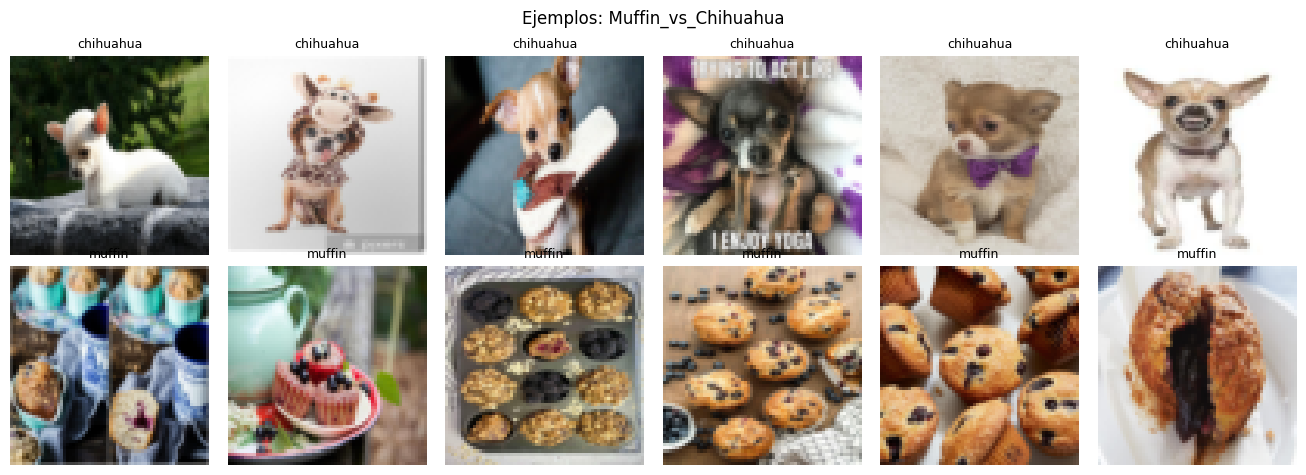

In [ ]:
def make_tf_datasets(bundle, batch_size):
    datasets = {}
    for split_name in ("train", "val", "test"):
        images, labels = bundle[split_name]
        dataset = tf.data.Dataset.from_tensor_slices((images, labels))
        if split_name == "train":
            dataset = dataset.shuffle(
                buffer_size=len(images),
                seed=SEED,
                reshuffle_each_iteration=True,
            )
        dataset = dataset.batch(batch_size)
        # uint8 -> float32 en [0, 1]
        dataset = dataset.map(
            lambda x, y: (tf.cast(x, tf.float32) / 255.0, y),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
        datasets[split_name] = dataset.prefetch(tf.data.AUTOTUNE)
    return datasets


BUNDLE["loaders"] = make_tf_datasets(BUNDLE, CONFIG["batch_size"])


def show_examples(bundle, per_class=6):
    """Muestra ejemplos aleatorios de train, una fila por clase."""
    images, labels = bundle["train"]
    rng = np.random.default_rng(SEED)
    n_classes = bundle["num_classes"]
    figure, axes = plt.subplots(n_classes, per_class, figsize=(2.2 * per_class, 2.4 * n_classes), squeeze=False)

    for class_index, class_name in enumerate(bundle["class_names"]):
        pool = np.flatnonzero(labels == class_index)
        chosen = rng.choice(pool, size=min(per_class, len(pool)), replace=False)
        for column, index in enumerate(chosen):
            axes[class_index, column].imshow(images[index])
            axes[class_index, column].set_title(class_name, fontsize=9)
        for axis in axes[class_index]:
            axis.axis("off")

    figure.suptitle(f"Ejemplos: {bundle['name']}")
    figure.tight_layout()
    plt.show()


show_examples(BUNDLE)

## 6. Arquitecturas CNN y tamaño de parámetros

Las tres variantes mantienen dos reducciones espaciales. Antes de las convoluciones hay un bloque de **aumento de datos** (volteo horizontal, rotación y zoom pequeños) que solo actúa en entrenamiento; en validación, test e inferencia no hace nada. Después, el modelo extrae mapas de características, aplica GlobalAveragePooling2D y pasa el vector por una cabeza MLP pequeña. La salida son 2 logits (muffin / chihuahua).

In [ ]:
MODEL_VARIANTS = {
    "pequeno": (16, 32),
    "mediano": (32, 64, 64),
    "grande": (128, 128, 64, 64),
}
USE_AUGMENTATION = True


def build_model(input_shape, num_classes, variant):
    inputs = keras.Input(shape=input_shape, name="image")
    x = inputs

    if USE_AUGMENTATION:
        x = layers.RandomFlip("horizontal", name="aug_flip")(x)
        x = layers.RandomRotation(0.08, name="aug_rotation")(x)
        x = layers.RandomZoom(0.10, name="aug_zoom")(x)

    channels = MODEL_VARIANTS[variant]
    pool_after = {0, len(channels) - 1}

    for layer_index, output_channels in enumerate(channels):
        x = layers.Conv2D(
            output_channels,
            kernel_size=3,
            padding="same",
            use_bias=False,
            name=f"conv_{layer_index + 1}",
        )(x)
        x = layers.BatchNormalization(name=f"batch_norm_{layer_index + 1}")(x)
        x = layers.ReLU(name=f"relu_{layer_index + 1}")(x)
        if layer_index in pool_after:
            x = layers.MaxPooling2D(pool_size=2, name=f"max_pool_{layer_index + 1}")(x)

    feature_maps = x
    pooled = layers.GlobalAveragePooling2D(name="global_average_pooling")(feature_maps)
    x = layers.Dense(64, activation="relu", name="classifier_dense")(pooled)
    x = layers.Dropout(0.20, name="classifier_dropout")(x)
    logits = layers.Dense(num_classes, dtype="float32", name="logits")(x)

    classifier = keras.Model(inputs=inputs, outputs=logits, name=f"cnn_{variant}")
    feature_model = keras.Model(inputs=inputs, outputs=feature_maps, name=f"cnn_{variant}_features")
    return classifier, feature_model


height, width = BUNDLE["input_shape"][:2]
print(f"Entrada {height}x{width}, tras 2 MaxPool {height // 4}x{width // 4}")
for variant in MODEL_VARIANTS:
    model, _ = build_model(BUNDLE["input_shape"], BUNDLE["num_classes"], variant)
    print(f"{variant:8s}: {model.count_params():,} parámetros")

# Resumen detallado del modelo mediano
build_model(BUNDLE["input_shape"], BUNDLE["num_classes"], "mediano")[0].summary()

Entrada 64x64, tras 2 MaxPool 16x16
pequeno : 7,474 parámetros
mediano : 61,090 parámetros
grande  : 267,330 parámetros


Model: "cnn_mediano"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_flip (RandomFlip)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_rotation (RandomRotation)   │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aug_zoom (RandomZoom)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_1 (Conv2D)                 │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (ReLU)                   │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool_1 (MaxPooling2D)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_2 (Conv2D)                 │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (ReLU)                   │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_3 (Conv2D)                 │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_3                    │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (ReLU)                   │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pool_3 (MaxPooling2D)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dense (Dense)        │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_dropout (Dropout)    │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logits (Dense)                  │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,090 (238.63 KB)

 Trainable params: 60,770 (237.38 KB)

 Non-trainable params: 320 (1.25 KB)

## 7. Funciones de entrenamiento

In [ ]:
def compile_model(model, learning_rate=1e-3):
    model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=learning_rate,
            weight_decay=1e-4,
        ),
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )


class BestValidationWeights(keras.callbacks.Callback):
    """Guarda y restaura los pesos del epoch con menor pérdida de validación."""
    def on_train_begin(self, logs=None):
        self.best_loss = float("inf")
        self.best_epoch = 0
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        val_loss = logs.get("val_loss")
        if val_loss is not None and val_loss < self.best_loss - 1e-4:
            self.best_loss = float(val_loss)
            self.best_epoch = epoch + 1
            self.best_weights = [weight.copy() for weight in self.model.get_weights()]

    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)


def fit_model(model, loaders, max_epochs, learning_rate=1e-3):
    compile_model(model, learning_rate)
    best_weights = BestValidationWeights()
    fit_history = model.fit(
        loaders["train"],
        validation_data=loaders["val"],
        epochs=max_epochs,
        callbacks=[best_weights],
        verbose=2,
    )
    history = pd.DataFrame(fit_history.history)
    history.insert(0, "epoch", np.arange(1, len(history) + 1))
    return model, history.to_dict(orient="records"), best_weights.best_epoch

## 8. Entrenamiento de los tres tamaños de CNN

In [ ]:
PROJECT_ROOT = Path.cwd()
MODEL_CHECKPOINT_DIR = PROJECT_ROOT / "artifacts" / "model_checkpoints" / "keras_cnn" / CONFIG["name"]
MODEL_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RETRAIN_MODELS = False  # Cambia a True para ignorar checkpoints y entrenar desde cero.
TRAINED_MODELS = {}


def checkpoint_paths(model_name):
    return (
        MODEL_CHECKPOINT_DIR / f"{model_name}.weights.h5",
        MODEL_CHECKPOINT_DIR / f"{model_name}.json",
    )


def checkpoint_matches(metadata_path, model_name, parameter_count):
    if RETRAIN_MODELS or not metadata_path.is_file():
        return False
    try:
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    except (OSError, json.JSONDecodeError):
        return False
    return (
        metadata.get("model") == model_name
        and metadata.get("input_shape") == list(BUNDLE["input_shape"])
        and metadata.get("num_classes") == BUNDLE["num_classes"]
        and metadata.get("epochs") == CONFIG["epochs"]
        and metadata.get("parameters") == int(parameter_count)
        and metadata.get("augmentation") == USE_AUGMENTATION
        and len(metadata.get("history", [])) == CONFIG["epochs"]
    )


for model_name in MODEL_VARIANTS:
    model, feature_model = build_model(
        input_shape=BUNDLE["input_shape"],
        num_classes=BUNDLE["num_classes"],
        variant=model_name,
    )
    parameter_count = model.count_params()
    weights_path, metadata_path = checkpoint_paths(model_name)
    reusable = weights_path.is_file() and checkpoint_matches(metadata_path, model_name, parameter_count)

    if reusable:
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        model.load_weights(weights_path)
        compile_model(model)
        history = metadata["history"]
        best_epoch = metadata["best_epoch"]
        print(f"\nModelo {model_name} | checkpoint cargado: {weights_path}")
    else:
        print(f"\nModelo {model_name} | parámetros entrenables: {parameter_count:,}")
        model, history, best_epoch = fit_model(
            model,
            BUNDLE["loaders"],
            max_epochs=CONFIG["epochs"],
        )
        model.save_weights(weights_path)
        metadata = {
            "dataset": CONFIG["name"],
            "model": model_name,
            "input_shape": list(BUNDLE["input_shape"]),
            "num_classes": BUNDLE["num_classes"],
            "epochs": CONFIG["epochs"],
            "parameters": int(parameter_count),
            "augmentation": USE_AUGMENTATION,
            "best_epoch": int(best_epoch),
            "history": history,
        }
        metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
        print(f"Checkpoint guardado en {weights_path}")

    TRAINED_MODELS[model_name] = {
        "model": model,
        "feature_model": feature_model,
        "history": history,
        "best_epoch": best_epoch,
        "parameters": parameter_count,
    }


Modelo pequeno | parámetros entrenables: 7,474
Epoch 1/40
126/126 - 13s - 104ms/step - accuracy: 0.7383 - loss: 0.5348 - val_accuracy: 0.5408 - val_loss: 0.9361
Epoch 2/40
126/126 - 1s - 12ms/step - accuracy: 0.8074 - loss: 0.4385 - val_accuracy: 0.5408 - val_loss: 1.5179
Epoch 3/40
126/126 - 3s - 20ms/step - accuracy: 0.8372 - loss: 0.3829 - val_accuracy: 0.5761 - val_loss: 0.9616
Epoch 4/40
126/126 - 1s - 12ms/step - accuracy: 0.8392 - loss: 0.3675 - val_accuracy: 0.5662 - val_loss: 1.0456
Epoch 5/40
126/126 - 1s - 12ms/step - accuracy: 0.8479 - loss: 0.3592 - val_accuracy: 0.8606 - val_loss: 0.3378
Epoch 6/40
126/126 - 2s - 13ms/step - accuracy: 0.8583 - loss: 0.3422 - val_accuracy: 0.8479 - val_loss: 0.3589
Epoch 7/40
126/126 - 2s - 15ms/step - accuracy: 0.8573 - loss: 0.3449 - val_accuracy: 0.7380 - val_loss: 0.4892
Epoch 8/40
126/126 - 1s - 12ms/step - accuracy: 0.8670 - loss: 0.3256 - val_accuracy: 0.6451 - val_loss: 0.7669
Epoch 9/40
126/126 - 1s - 12ms/step - accuracy: 0.8598

## Curvas de entrenamiento

La figura compara los tres tamaños. La línea sólida muestra train y la discontinua validation. Se guarda en PNG.

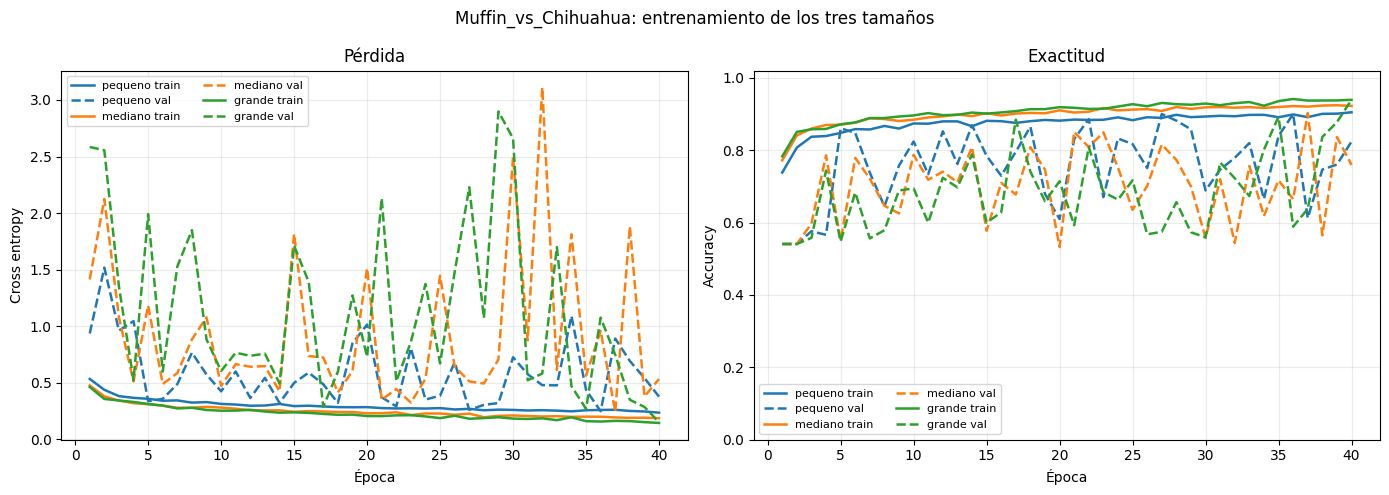

Gráfica guardada en /content/artifacts/keras_cnn_training_curves/Muffin_vs_Chihuahua_curvas.png


In [ ]:
TRAINING_PLOT_DIR = PROJECT_ROOT / "artifacts" / "keras_cnn_training_curves"
TRAINING_PLOT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_COLORS = {"pequeno": "#1f77b4", "mediano": "#ff7f0e", "grande": "#2ca02c"}

figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(14, 5))
for model_name in MODEL_VARIANTS:
    history = pd.DataFrame(TRAINED_MODELS[model_name]["history"])
    epochs = history["epoch"]
    color = MODEL_COLORS[model_name]
    loss_axis.plot(epochs, history["loss"], color=color, linestyle="-", linewidth=1.8, label=f"{model_name} train")
    loss_axis.plot(epochs, history["val_loss"], color=color, linestyle="--", linewidth=1.8, label=f"{model_name} val")
    accuracy_axis.plot(epochs, history["accuracy"], color=color, linestyle="-", linewidth=1.8, label=f"{model_name} train")
    accuracy_axis.plot(epochs, history["val_accuracy"], color=color, linestyle="--", linewidth=1.8, label=f"{model_name} val")

loss_axis.set_title("Pérdida")
loss_axis.set_xlabel("Época")
loss_axis.set_ylabel("Cross entropy")
loss_axis.grid(alpha=0.25)
loss_axis.legend(ncol=2, fontsize=8)

accuracy_axis.set_title("Exactitud")
accuracy_axis.set_xlabel("Época")
accuracy_axis.set_ylabel("Accuracy")
accuracy_axis.set_ylim(0, 1.02)
accuracy_axis.grid(alpha=0.25)
accuracy_axis.legend(ncol=2, fontsize=8)

figure.suptitle(f"{CONFIG['name']}: entrenamiento de los tres tamaños")
figure.tight_layout()
output_path = TRAINING_PLOT_DIR / f"{CONFIG['name']}_curvas.png"
figure.savefig(output_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(figure)
print(f"Gráfica guardada en {output_path}")

## 9. Evaluación en test

In [ ]:
evaluation_rows = []
for model_name in MODEL_VARIANTS:
    record = TRAINED_MODELS[model_name]
    metrics = record["model"].evaluate(BUNDLE["loaders"]["test"], verbose=0, return_dict=True)
    evaluation_rows.append({
        "model": model_name,
        "parameters": record["parameters"],
        "best_epoch": record["best_epoch"],
        "test_loss": float(metrics["loss"]),
        "test_accuracy": float(metrics["accuracy"]),
    })

results_df = pd.DataFrame(evaluation_rows)
results_df

,model,parameters,best_epoch,test_loss,test_accuracy
0,pequeno,7474,36,0.232639,0.902872
1,mediano,61090,37,0.244253,0.899493
2,grande,267330,40,0.169791,0.935811


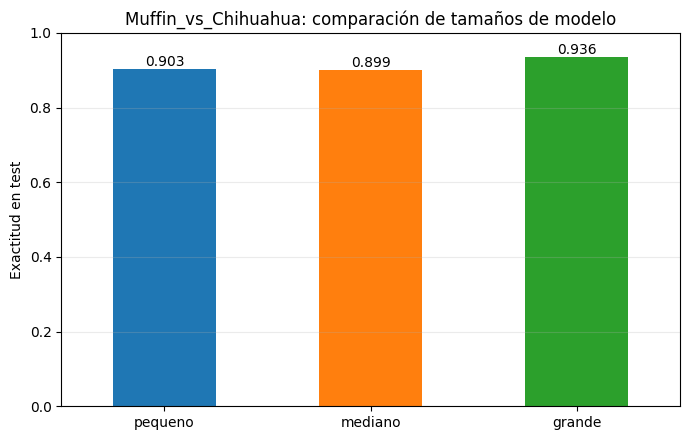

In [ ]:
ax = results_df.set_index("model")["test_accuracy"].reindex(list(MODEL_VARIANTS)).plot(
    kind="bar", figsize=(7, 4.5), ylim=(0, 1), rot=0,
    color=[MODEL_COLORS[m] for m in MODEL_VARIANTS],
)
for patch in ax.patches:
    ax.annotate(f"{patch.get_height():.3f}", (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_ylabel("Exactitud en test")
ax.set_xlabel("")
ax.set_title(f"{CONFIG['name']}: comparación de tamaños de modelo")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Matrices de confusión y reporte por clase

Con dos clases similares visualmente, la exactitud global puede esconder qué clase se confunde más. Aquí se ve cuántos chihuahuas se predicen como muffins y viceversa.

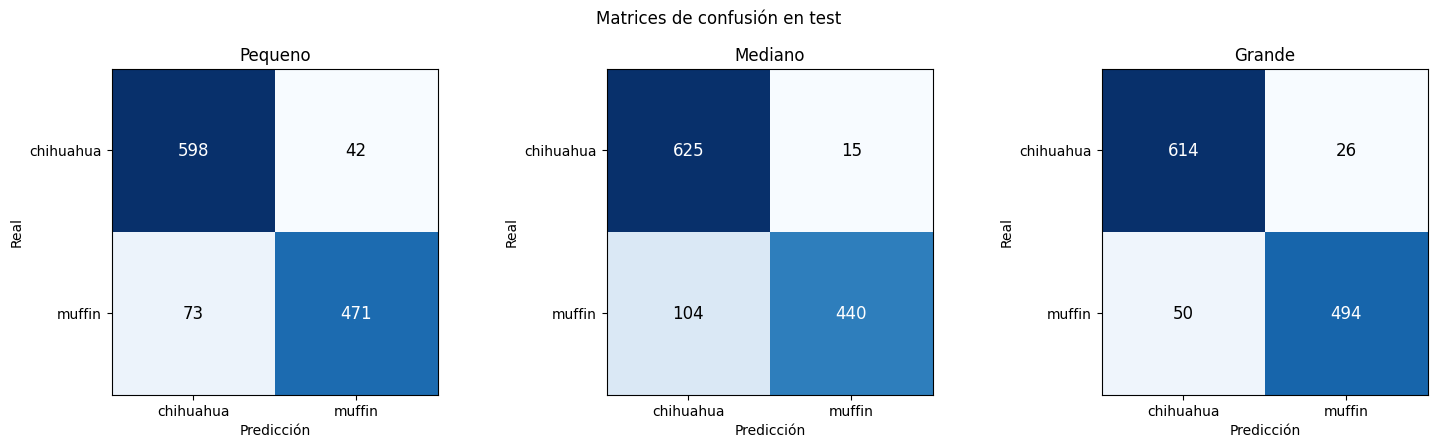

Mejor modelo en test: grande

              precision    recall  f1-score   support

   chihuahua      0.925     0.959     0.942       640
      muffin      0.950     0.908     0.929       544

    accuracy                          0.936      1184
   macro avg      0.937     0.934     0.935      1184
weighted avg      0.936     0.936     0.936      1184



In [ ]:
def predict_labels(model, loader):
    logits = model.predict(loader, verbose=0)
    return np.argmax(logits, axis=1)


y_true = BUNDLE["test"][1]
PREDICTIONS = {name: predict_labels(TRAINED_MODELS[name]["model"], BUNDLE["loaders"]["test"]) for name in MODEL_VARIANTS}

figure, axes = plt.subplots(1, len(MODEL_VARIANTS), figsize=(5 * len(MODEL_VARIANTS), 4.5))
for axis, model_name in zip(axes, MODEL_VARIANTS):
    matrix = confusion_matrix(y_true, PREDICTIONS[model_name], labels=range(BUNDLE["num_classes"]))
    axis.imshow(matrix, cmap="Blues")
    axis.set_title(model_name.capitalize())
    axis.set_xticks(range(BUNDLE["num_classes"]))
    axis.set_yticks(range(BUNDLE["num_classes"]))
    axis.set_xticklabels(BUNDLE["class_names"])
    axis.set_yticklabels(BUNDLE["class_names"])
    axis.set_xlabel("Predicción")
    axis.set_ylabel("Real")
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            axis.text(j, i, int(matrix[i, j]), ha="center", va="center",
                      color="white" if matrix[i, j] > matrix.max() / 2 else "black", fontsize=12)
figure.suptitle("Matrices de confusión en test")
figure.tight_layout()
plt.show()

BEST_MODEL_NAME = results_df.sort_values("test_accuracy", ascending=False).iloc[0]["model"]
print(f"Mejor modelo en test: {BEST_MODEL_NAME}\n")
print(classification_report(y_true, PREDICTIONS[BEST_MODEL_NAME], target_names=BUNDLE["class_names"], digits=3))

### Ejemplos mal clasificados del mejor modelo

grande: 76 errores de 1184 imágenes de test


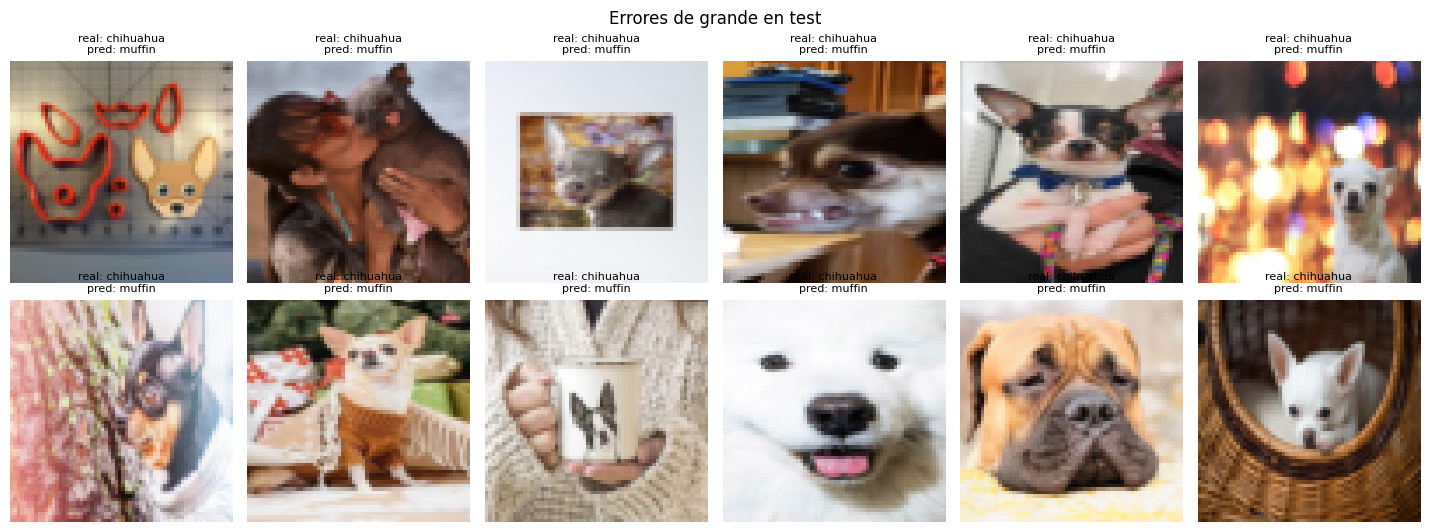

In [ ]:
wrong = np.flatnonzero(PREDICTIONS[BEST_MODEL_NAME] != y_true)
print(f"{BEST_MODEL_NAME}: {len(wrong)} errores de {len(y_true)} imágenes de test")

if len(wrong):
    shown = wrong[:12]
    columns = 6
    rows = math.ceil(len(shown) / columns)
    figure, axes = plt.subplots(rows, columns, figsize=(2.4 * columns, 2.7 * rows), squeeze=False)
    axes = axes.reshape(-1)
    for axis, index in zip(axes, shown):
        axis.imshow(BUNDLE["test"][0][index])
        real = BUNDLE["class_names"][int(y_true[index])]
        pred = BUNDLE["class_names"][int(PREDICTIONS[BEST_MODEL_NAME][index])]
        axis.set_title(f"real: {real}\npred: {pred}", fontsize=8)
        axis.axis("off")
    for axis in axes[len(shown):]:
        axis.axis("off")
    figure.suptitle(f"Errores de {BEST_MODEL_NAME} en test")
    figure.tight_layout()
    plt.show()

## 10. Inferencia y mapas de características por clase

Para cada clase se toma una imagen de test. Cada fila representa una clase y cada columna un tamaño de CNN. Los canales de la última convolución se promedian para conservar un único mapa espacial 2D (`H × W`) antes del average pooling global. Debajo de cada mapa se muestra la predicción. A la izquierda se incluye la imagen original para comparar qué zonas activa cada modelo. La escala de color es común entre clases y tamaños.

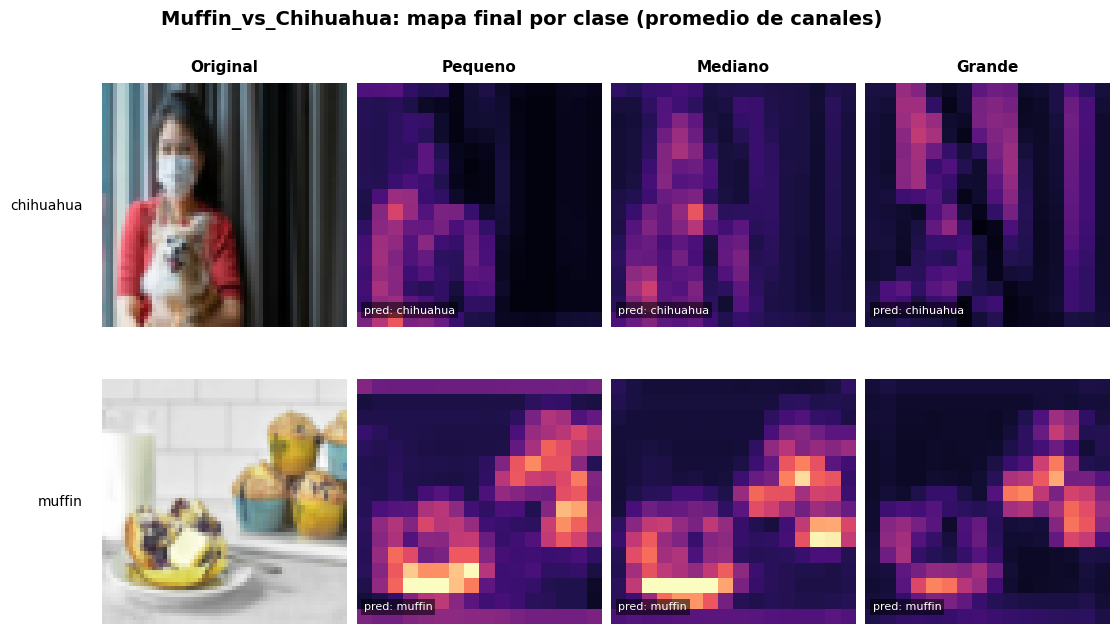

Mapas 2D guardados en /content/artifacts/keras_cnn_feature_maps/Muffin_vs_Chihuahua_features_por_clase.png


In [ ]:
FEATURE_DIR = PROJECT_ROOT / "artifacts" / "keras_cnn_feature_maps"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)


def infer_averaged_feature_map(model, feature_model, image_uint8):
    """Promedia los canales de la última convolución y conserva el mapa 2D."""
    batch = tf.convert_to_tensor(image_uint8[None, ...].astype(np.float32) / 255.0)
    feature_maps = feature_model(batch, training=False).numpy()[0]  # (alto, ancho, canales)
    averaged_map = feature_maps.astype(np.float32).mean(axis=-1)
    logits = model(batch, training=False).numpy()[0]
    return averaged_map, int(np.argmax(logits))


def plot_class_feature_maps(bundle, samples, class_outputs, output_path):
    """Una fila por clase: imagen original + una columna por tamaño de CNN."""
    class_count = len(bundle["class_names"])
    figure, axes = plt.subplots(
        class_count,
        len(MODEL_VARIANTS) + 1,
        figsize=(12, max(4.5, class_count * 3.2)),
        squeeze=False,
    )

    all_values = np.concatenate([
        feature_map.ravel()
        for class_entry in class_outputs.values()
        for feature_map, _ in class_entry.values()
    ])
    shared_map_max = max(float(np.quantile(all_values, 0.995)), 1e-6)

    for class_index, class_name in enumerate(bundle["class_names"]):
        axes[class_index, 0].imshow(samples[class_index])
        axes[class_index, 0].set_axis_off()
        axes[class_index, 0].text(-0.08, 0.5, class_name, transform=axes[class_index, 0].transAxes,
                                  ha="right", va="center", fontsize=10, clip_on=False)
        if class_index == 0:
            axes[class_index, 0].set_title("Original", fontsize=11, weight="bold", pad=8)

        for column_index, model_name in enumerate(MODEL_VARIANTS, start=1):
            axis = axes[class_index, column_index]
            feature_map, predicted_index = class_outputs[class_index][model_name]
            axis.imshow(feature_map, cmap="magma", vmin=0, vmax=shared_map_max, interpolation="nearest")
            axis.set_axis_off()
            if class_index == 0:
                axis.set_title(model_name.capitalize(), fontsize=11, weight="bold", pad=8)
            axis.text(0.03, 0.05, f"pred: {bundle['class_names'][predicted_index]}",
                      transform=axis.transAxes, ha="left", va="bottom", fontsize=8, color="white",
                      bbox={"facecolor": "black", "alpha": 0.55, "pad": 2, "edgecolor": "none"})

    figure.suptitle(f"{bundle['name']}: mapa final por clase (promedio de canales)",
                    fontsize=14, weight="bold", y=0.995)
    figure.subplots_adjust(top=0.90, bottom=0.015, left=0.15, right=0.99, wspace=0.04, hspace=0.10)
    figure.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(figure)


test_images, test_labels = BUNDLE["test"]
samples, class_outputs = {}, {}

for class_index, class_name in enumerate(BUNDLE["class_names"]):
    matching_indices = np.flatnonzero(test_labels == class_index)
    if len(matching_indices) == 0:
        raise ValueError(f"La clase {class_name} no aparece en test.")
    sample = test_images[int(matching_indices[0])]
    samples[class_index] = sample
    class_outputs[class_index] = {}
    for model_name in MODEL_VARIANTS:
        record = TRAINED_MODELS[model_name]
        class_outputs[class_index][model_name] = infer_averaged_feature_map(
            record["model"], record["feature_model"], sample
        )

image_path = FEATURE_DIR / f"{CONFIG['name']}_features_por_clase.png"
plot_class_feature_maps(BUNDLE, samples, class_outputs, image_path)
print(f"Mapas 2D guardados en {image_path}")